# Лабораторная работа №2

**Многомерный статистический анализ**

Выполнили:<br>
Апрелков Михаил 465037<br>
Воронин Илья 372736

In [1]:
import warnings
from collections.abc import Callable
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from scipy import integrate, optimize, stats

SEED = 20261021

PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
INK, INK2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 110,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'grid.linestyle': '-', 'axes.axisbelow': True,
    'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.prop_cycle': cycler(color=PALETTE),
    'xtick.color': AXIS, 'ytick.color': AXIS, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'lines.linewidth': 1.8, 'lines.solid_capstyle': 'round', 'lines.solid_joinstyle': 'round',
    'legend.frameon': False, 'legend.fontsize': 9, 'font.size': 10,
})
REF = dict(color=INK, lw=0.8)
BOUND = dict(lw=1.0, ls=(0, (4, 3)))
COLORS = {'среднее': INK2, 'медиана': PALETTE[2], 'усечённое 10 %': PALETTE[3], 'усечённое 25 %': PALETTE[4],
          'Хьюбер': PALETTE[1], 'bisquare': PALETTE[0]}
Q_PHI = stats.norm.ppf(0.75)


def show(df, fmt='{:.4f}', formats=None):
    styler = df.style.format(fmt, na_rep='—')
    if formats:
        styler = styler.format(formats, na_rep='—')
    return styler


def _z(t, c):
    return (np.asarray(t, dtype=float) / c) ** 2


@dataclass
class Psi:
    name: str
    psi: Callable
    dpsi: Callable
    w: Callable
    sup: Callable


HUBER = Psi('Хьюбер',
            psi=lambda t, k: np.clip(t, -k, k),
            dpsi=lambda t, k: np.where(np.abs(t) <= k, 1.0, 0.0),
            w=lambda t, k: np.minimum(1.0, k / np.maximum(np.abs(t), 1e-300)),
            sup=lambda k: k)
BISQ = Psi('bisquare',
           psi=lambda t, c: t * (1 - np.minimum(_z(t, c), 1)) ** 2,
           dpsi=lambda t, c: np.where(_z(t, c) <= 1, (1 - _z(t, c)) * (1 - 5 * _z(t, c)), 0.0),
           w=lambda t, c: (1 - np.minimum(_z(t, c), 1)) ** 2,
           sup=lambda c: 16 * c / (25 * np.sqrt(5)))


def m_location(x, P, c, scale=1.0, tol=1e-10, maxit=2000):
    x = np.atleast_2d(np.asarray(x, dtype=float))
    s = np.broadcast_to(np.asarray(scale, dtype=float), (len(x),))
    mu = np.median(x, axis=1)
    for _ in range(maxit):
        w = P.w((x - mu[:, None]) / s[:, None], c)
        mu_new = np.sum(w * x, axis=1) / np.sum(w, axis=1)
        converged = np.all(np.abs(mu_new - mu) <= tol * s)
        mu = mu_new
        if converged:
            break
    else:
        warnings.warn('m_location: итерации не сошлись')
    return mu


def mad(x):
    x = np.atleast_2d(np.asarray(x, dtype=float))
    return np.median(np.abs(x - np.median(x, axis=1, keepdims=True)), axis=1)


def expect(g, pdf, pts=()):
    edges = [-np.inf, *sorted({0.0, *(s * p for p in pts for s in (-1.0, 1.0))}), np.inf]
    return sum(integrate.quad(lambda u: g(u) * pdf(u), a, b, limit=500, epsabs=1e-12, epsrel=1e-11)[0]
               for a, b in zip(edges[:-1], edges[1:]))


def trunc_norm(c, mmax=5):
    N = np.empty(mmax + 1)
    N[0] = 2 * stats.norm.cdf(c) - 1
    for m in range(1, mmax + 1):
        N[m] = (2 * m - 1) * N[m - 1] - 2 * c ** (2 * m - 1) * stats.norm.pdf(c)
    return N


def trunc_cauchy(c, g, mmax=5):
    C = np.empty(mmax + 1)
    J = 2 / g * np.arctan(c / g)
    C[0] = g / np.pi * J
    for m in range(1, mmax + 1):
        J = 2 * c ** (2 * m - 1) / (2 * m - 1) - g ** 2 * J
        C[m] = g / np.pi * J
    return C


def moments(P, c, T):
    if P is HUBER:
        return T[0], T[1] + c ** 2 * (1 - T[0])
    a = T / c ** (2 * np.arange(len(T)))
    return a[0] - 6 * a[1] + 5 * a[2], c ** 2 * (a[1] - 4 * a[2] + 6 * a[3] - 4 * a[4] + a[5])


def av_norm(P, c):
    e_dpsi, e_psi2 = moments(P, c, trunc_norm(c))
    return e_psi2 / e_dpsi ** 2

## Задание 1

Беру модель сдвига $X\sim N(\mu,1)$, $\sigma=1$ известна (по эквивариантности считаю при $\mu=0$, $F=\Phi$). Оценки: среднее, медиана, усечённое среднее $\bar x_{0.1}$ и M-оценки с ограниченной $\psi$ — Хьюбер ($k=1.345$) и bisquare ($c=4.685$).

Для M-оценки $\mathrm{IF}(x)=\psi(x)/\mathrm E\psi'(Z)$, отсюда
$$
\mathrm{IF}_{\bar x}(x)=x,\qquad
\mathrm{IF}_{\mathrm{med}}(x)=\frac{\operatorname{sign}x}{2\varphi(0)},\qquad
\mathrm{IF}_{\bar x_\alpha}(x)=\frac{\max\{-k_\alpha,\min(k_\alpha,x)\}}{1-2\alpha},\ \ k_\alpha=\Phi^{-1}(1-\alpha),
$$
$$
\mathrm{IF}_{H}(x)=\frac{\psi_k(x)}{2\Phi(k)-1},\qquad
\mathrm{IF}_{B}(x)=\frac{\psi_c(x)}{\mathrm E\psi_c'(Z)},\qquad \psi_c(x)=x\big(1-x^2/c^2\big)^2\,\mathbb 1\{|x|\le c\}.
$$
GES $\gamma^*=\sup_x|\mathrm{IF}(x)|$; у bisquare максимум $\psi_c$ в точке $x=c/\sqrt5$:
$$
\gamma^*_{\bar x}=\infty,\qquad \gamma^*_{\mathrm{med}}=\sqrt{\pi/2},\qquad \gamma^*_{\bar x_\alpha}=\frac{k_\alpha}{1-2\alpha},\qquad
\gamma^*_H=\frac{k}{2\Phi(k)-1},\qquad \gamma^*_B=\frac{16c}{25\sqrt5\,\mathrm E\psi_c'} .
$$
IF проверяю через sensitivity curve $\mathrm{SC}_n(x)=n\big(T_n(x_1,\dots,x_{n-1},x)-T_{n-1}(x_1,\dots,x_{n-1})\big)$ на выборке $x_i=\Phi^{-1}(i/n)$, $n=200$.

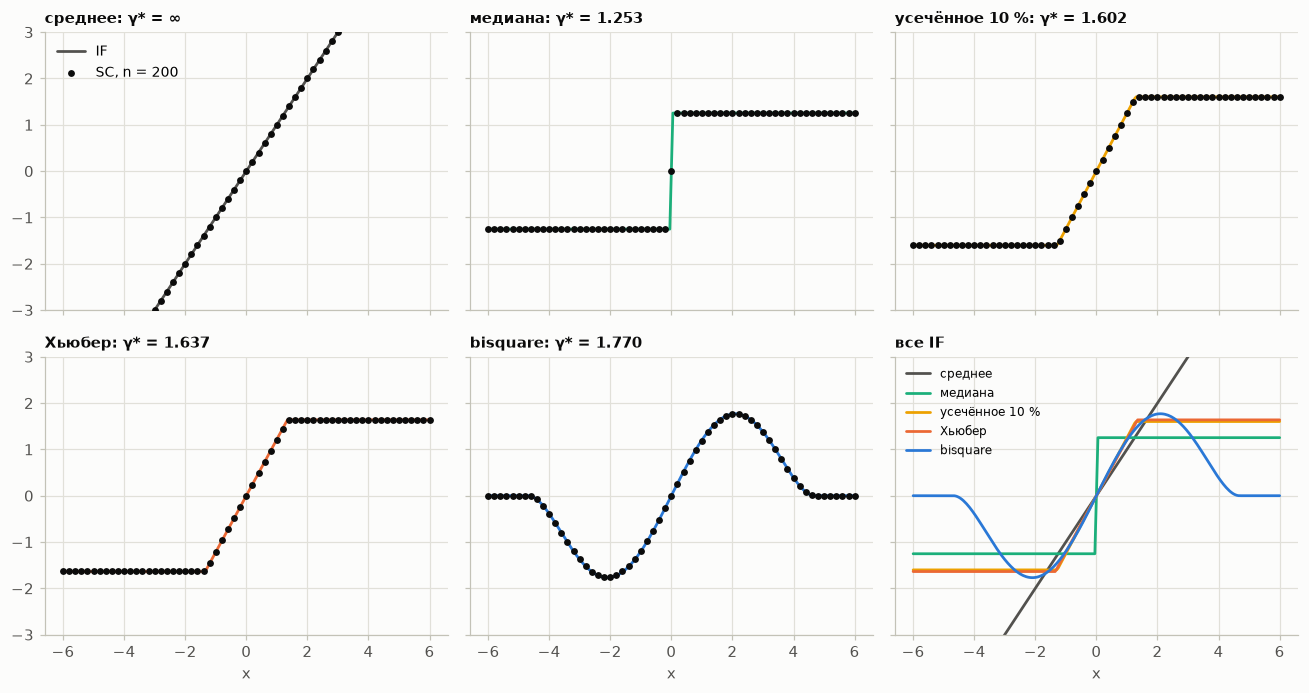

,γ* (формула),max |SC|
оценка,,
среднее,inf,6.0000
медиана,1.253314,1.2533
усечённое 10 %,1.601939,1.6019
Хьюбер,1.637499,1.6351
bisquare,1.769554,1.7618


In [2]:
ALPHA, K_H, C_B = 0.1, 1.345, 4.685
K_TR = stats.norm.ppf(1 - ALPHA)
E_DPSI_H = moments(HUBER, K_H, trunc_norm(K_H))[0]
E_DPSI_B = moments(BISQ, C_B, trunc_norm(C_B))[0]

ESTIMATORS = {
    'среднее': lambda x: np.mean(x, axis=1),
    'медиана': lambda x: np.median(x, axis=1),
    'усечённое 10 %': lambda x: stats.trim_mean(x, ALPHA, axis=1),
    'Хьюбер': lambda x: m_location(x, HUBER, K_H),
    'bisquare': lambda x: m_location(x, BISQ, C_B),
}
IF = {
    'среднее': lambda x: np.asarray(x, dtype=float),
    'медиана': lambda x: np.sign(x) / (2 * stats.norm.pdf(0)),
    'усечённое 10 %': lambda x: np.clip(x, -K_TR, K_TR) / (1 - 2 * ALPHA),
    'Хьюбер': lambda x: HUBER.psi(x, K_H) / E_DPSI_H,
    'bisquare': lambda x: BISQ.psi(x, C_B) / E_DPSI_B,
}
GES = {
    'среднее': np.inf,
    'медиана': 1 / (2 * stats.norm.pdf(0)),
    'усечённое 10 %': K_TR / (1 - 2 * ALPHA),
    'Хьюбер': HUBER.sup(K_H) / E_DPSI_H,
    'bisquare': BISQ.sup(C_B) / E_DPSI_B,
}

n_sc = 200
base = stats.norm.ppf(np.arange(1, n_sc) / n_sc)
xs = np.linspace(-6, 6, 241)
grid = np.column_stack([np.tile(base, (len(xs), 1)), xs])
SC = {name: n_sc * (est(grid) - est(base[None, :])[0]) for name, est in ESTIMATORS.items()}

fig, axes = plt.subplots(2, 3, figsize=(12, 6.4), sharex=True, sharey=True)
for ax, name in zip(axes.flat, ESTIMATORS):
    ax.plot(xs, IF[name](xs), color=COLORS[name], label='IF')
    ax.scatter(xs[::4], SC[name][::4], s=12, color=INK, zorder=3, label='SC, n = 200')
    ges = '∞' if np.isinf(GES[name]) else f'{GES[name]:.3f}'
    ax.set_title(f'{name}: γ* = {ges}', fontsize=10)
ax = axes.flat[-1]
for name in ESTIMATORS:
    ax.plot(xs, IF[name](xs), color=COLORS[name], label=name)
ax.set_title('все IF', fontsize=10)
ax.legend(loc='upper left', fontsize=8)
axes[0, 0].legend(loc='upper left')
axes[0, 0].set_ylim(-3, 3)
for ax in axes[1]:
    ax.set_xlabel('x')
fig.tight_layout()
plt.show()

show(pd.DataFrame({'γ* (формула)': GES,
                   'max |SC|': {name: np.max(np.abs(SC[name])) for name in ESTIMATORS}}).rename_axis('оценка'),
     formats={'max |SC|': '{:.4f}'})

SC совпадает с IF. У среднего $\gamma^*=\infty$ (на сетке $|x|\le6$ видно только до 6). Хьюбер и bisquare с одинаковой эффективностью 95 %, но у Хьюбера $\gamma^*$ меньше: 1.64 против 1.77. Это оптимальность Хьюбера по Хампелю: при заданной AV у него минимальный $\gamma^*$.

Проверка $v^2=\mathrm E_F\,\mathrm{IF}(X,F)^2$ тремя способами: интеграл, среднее $\mathrm{IF}(X_i)^2$ по $10^6$ точкам и $n\,\mathrm{Var}(T_n)$ по Монте-Карло ($n=400$, $M=4000$, погрешность около $\pm4.5\,\%$):

In [3]:
rng = np.random.default_rng(SEED + 1)
n, M = 400, 4000
X = rng.standard_normal((M, n))
z = rng.standard_normal(1_000_000)
kinks = {'среднее': (), 'медиана': (), 'усечённое 10 %': (K_TR,), 'Хьюбер': (K_H,), 'bisquare': (C_B,)}
rows = []
for name, est in ESTIMATORS.items():
    t = est(X)
    rows.append({'оценка': name,
                 'E IF² (интеграл)': expect(lambda u, f=IF[name]: f(u) ** 2, stats.norm.pdf, kinks[name]),
                 'среднее IF(X_i)²': np.mean(IF[name](z) ** 2),
                 'n·Var(T) (МК)': n * t.var()})
v2 = pd.DataFrame(rows).set_index('оценка')
v2['отклонение МК, %'] = 100 * (v2['n·Var(T) (МК)'] / v2['E IF² (интеграл)'] - 1)
show(v2, formats={'отклонение МК, %': '{:.1f}'})

,E IF² (интеграл),среднее IF(X_i)²,n·Var(T) (МК),"отклонение МК, %"
оценка,,,,
среднее,1.000000,1.000696,0.997982,-0.2
медиана,1.570796,1.570796,1.536187,-2.2
усечённое 10 %,1.060398,1.060459,1.047849,-1.2
Хьюбер,1.052631,1.052791,1.040708,-1.1
bisquare,1.052635,1.053098,1.043544,-0.9


Все три способа совпадают (расхождения Монте-Карло до 2.2 %), т.е. $v^2=\mathrm E_F\,\mathrm{IF}^2$ подтверждается.

## Задание 2

Беру усечённое среднее $\bar x_{0.25}$, у него $\varepsilon^*=0.25$. Для сравнения — среднее ($\varepsilon^*=0$), $\bar x_{0.1}$ ($\varepsilon^*=0.1$) и медиана ($\varepsilon^*=0.5$).

Информативность считаю как $R^2=\operatorname{corr}^2(T,\mu)$. В каждом повторении $\mu\sim U(-5,5)$, $X_i=\mu+Z_i$, $n=100$, и доля $\varepsilon$ наблюдений заменяется на точку $x_0\sim U(-1000,1000)$, не связанную с $\mu$. Пока оценка держится, $T\approx\mu$ и $R^2\approx1$; после срыва $T$ определяется выбросами и $R^2\approx0$.

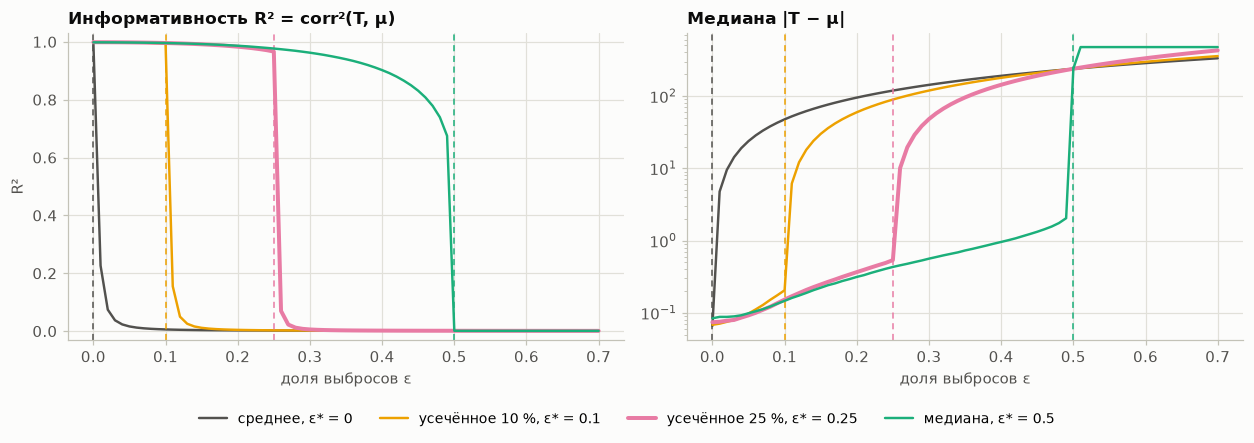

,среднее,усечённое 10 %,усечённое 25 %,медиана
ε,,,,
0.000000,0.999,0.999,0.999,0.998
0.050000,0.016,0.998,0.998,0.998
0.100000,0.006,0.994,0.996,0.996
0.110000,0.005,0.155,0.995,0.995
0.200000,0.003,0.004,0.983,0.986
0.250000,0.002,0.003,0.966,0.977
0.260000,0.002,0.003,0.070,0.974
0.300000,0.002,0.002,0.006,0.962
0.450000,0.001,0.001,0.001,0.831


In [4]:
rng = np.random.default_rng(SEED + 2)
n, R = 100, 2000
eps_grid = np.round(np.arange(0, 0.701, 0.01), 2)
mu_true = rng.uniform(-5, 5, R)
Z = rng.standard_normal((R, n))
x0 = rng.uniform(-1000, 1000, R)
EST2 = {
    'среднее': (lambda x: np.mean(x, axis=1), 0.0),
    'усечённое 10 %': (lambda x: stats.trim_mean(x, 0.1, axis=1), 0.1),
    'усечённое 25 %': (lambda x: stats.trim_mean(x, 0.25, axis=1), 0.25),
    'медиана': (lambda x: np.median(x, axis=1), 0.5),
}
r2 = {name: np.empty(len(eps_grid)) for name in EST2}
err = {name: np.empty(len(eps_grid)) for name in EST2}
for j, e in enumerate(eps_grid):
    X = mu_true[:, None] + Z
    X[:, :int(round(e * n))] = x0[:, None]
    for name, (est, _) in EST2.items():
        t = est(X)
        r2[name][j] = np.corrcoef(t, mu_true)[0, 1] ** 2
        err[name][j] = np.median(np.abs(t - mu_true))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0), sharex=True)
for name, (_, bp) in EST2.items():
    lw = 2.6 if name == 'усечённое 25 %' else 1.6
    axes[0].plot(eps_grid, r2[name], color=COLORS[name], lw=lw, label=f'{name}, ε* = {bp:g}')
    axes[1].semilogy(eps_grid, err[name], color=COLORS[name], lw=lw)
    for ax in axes:
        ax.axvline(bp, color=COLORS[name], **BOUND)
axes[0].set(title='Информативность R² = corr²(T, μ)', xlabel='доля выбросов ε', ylabel='R²', ylim=(-0.03, 1.03))
axes[1].set(title='Медиана |T − μ|', xlabel='доля выбросов ε')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

sel = [0.0, 0.05, 0.1, 0.11, 0.2, 0.25, 0.26, 0.3, 0.45, 0.49, 0.5, 0.6]
idx = [int(np.argmin(np.abs(eps_grid - e))) for e in sel]
show(pd.DataFrame({name: r2[name][idx] for name in EST2},
                  index=pd.Index(sel, name='ε')), '{:.3f}')

У $\bar x_{0.25}$ $R^2\ge0.97$ вплоть до $\varepsilon=0.25$ и падает до 0.07 при $\varepsilon=0.26$: при $n=100$ отрезается 25 наблюдений с каждой стороны, и 26-й выброс уже попадает в среднее. С остальными оценками то же: среднее теряет информативность сразу, $\bar x_{0.1}$ — после 0.1, медиана — после 0.5. Перед $\varepsilon^*$ информативность тоже немного снижается, потому что растёт смещение: у медианы оно $\Phi^{-1}\big(\tfrac1{2(1-\varepsilon)}\big)\to\infty$ при $\varepsilon\to0.5$, поэтому $R^2=0.83$ при $\varepsilon=0.45$ и $0.68$ при $\varepsilon=0.49$.

## Задание 3

### 3.1–3.2. Нормальная модель, масштаб — MAD

$X\sim N(\mu,\sigma^2)$, $\hat\sigma=\mathrm{MADN}=\mathrm{MAD}/0.6745$, $\hat\mu$ — решение $\sum\psi\big((x_i-\hat\mu)/\hat\sigma\big)=0$. При симметричном $F$ разброс $\hat\sigma$ на AV не влияет ($\mathrm E\,\psi'(Z)Z=0$), поэтому
$$
\mathrm{eff}=\frac{(\mathrm E\psi')^2}{\mathrm E\psi^2},\qquad
\text{Хьюбер: }\ \mathrm E\psi'=2\Phi(k)-1,\ \ \mathrm E\psi^2=2\Phi(k)-1-2k\varphi(k)+2k^2\big(1-\Phi(k)\big).
$$
Для bisquare — через усечённые моменты $N_0=2\Phi(c)-1$, $N_m=(2m-1)N_{m-1}-2c^{2m-1}\varphi(c)$ (как в ЛР1). Константы нахожу из $\mathrm{eff}=\Delta$:

,k (Хьюбер),c (bisquare)
Δ,,
0.800000,0.5294,3.1369
0.900000,0.9818,3.8827
0.950000,1.3450,4.6851
0.990000,2.0102,7.0414


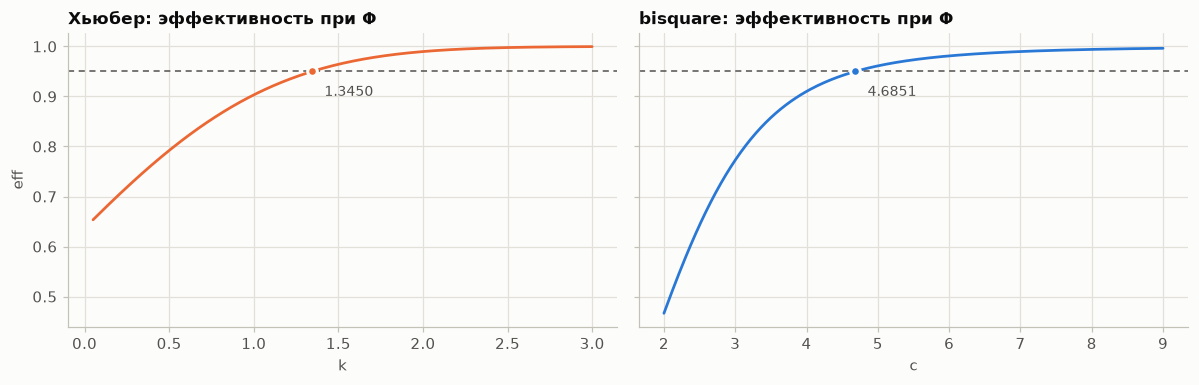

Хьюбер, 1.3450: эффективность по МК = 0.959
bisquare, 4.6851: эффективность по МК = 0.958


In [5]:
rows = []
for d in [0.80, 0.90, 0.95, 0.99]:
    rows.append({'Δ': d,
                 'k (Хьюбер)': optimize.brentq(lambda k, d=d: 1 / av_norm(HUBER, k) - d, 0.05, 6),
                 'c (bisquare)': optimize.brentq(lambda c, d=d: 1 / av_norm(BISQ, c) - d, 1.5, 20)})
display(show(pd.DataFrame(rows).set_index('Δ')))

DELTA = 0.95
K95 = optimize.brentq(lambda k: 1 / av_norm(HUBER, k) - DELTA, 0.05, 6)
C95 = optimize.brentq(lambda c: 1 / av_norm(BISQ, c) - DELTA, 1.5, 20)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, P, grid_c, c95 in [(axes[0], HUBER, np.linspace(0.05, 3, 300), K95), (axes[1], BISQ, np.linspace(2, 9, 300), C95)]:
    ax.plot(grid_c, [1 / av_norm(P, c) for c in grid_c], color=COLORS[P.name])
    ax.axhline(DELTA, color=INK2, **BOUND)
    ax.scatter([c95], [DELTA], s=40, color=COLORS[P.name], edgecolor=SURFACE, linewidth=2, zorder=4)
    ax.annotate(f'{c95:.4f}', (c95, DELTA), xytext=(8, -16), textcoords='offset points', fontsize=9, color=INK2)
    ax.set(title=f'{P.name}: эффективность при Φ', xlabel='k' if P is HUBER else 'c')
axes[0].set_ylabel('eff')
fig.tight_layout()
plt.show()

rng = np.random.default_rng(SEED + 3)
n, M = 400, 4000
X = 10 + 2 * rng.standard_normal((M, n))
S = mad(X) / Q_PHI
for P, c in [(HUBER, K95), (BISQ, C95)]:
    mu = m_location(X, P, c, S)
    print(f'{P.name}, {c:.4f}: эффективность по МК = {4 / (n * mu.var()):.3f}')

При $\Delta=0.95$ получились стандартные $k=1.345$ и $c=4.685$. Моделирование с MADN даёт эффективность 0.96, т.е. 0.95 в пределах погрешности.

### 3.3. Maximum bias через GES

$\gamma^*=\lim_{\varepsilon\to0}\mathrm{MB}(\varepsilon)/\varepsilon$, поэтому $\mathrm{MB}(\varepsilon)\approx\varepsilon\gamma^*$, где
$$
\gamma^*_H=\frac{k}{2\Phi(k)-1}\,\sigma,\qquad \gamma^*_B=\frac{16c}{25\sqrt5\,\mathrm E\psi_c'}\,\sigma
$$
(MAD на IF оценки $\hat\mu$ при симметричном $F$ не влияет, как и на AV).

In [6]:
GES_H = HUBER.sup(K95) / moments(HUBER, K95, trunc_norm(K95))[0]
GES_B = BISQ.sup(C95) / moments(BISQ, C95, trunc_norm(C95))[0]
EPS_LIST = [0.01, 0.05, 0.1, 0.2]
mb_approx = pd.DataFrame({'Хьюбер: ε·γ*': [e * GES_H for e in EPS_LIST],
                          'bisquare: ε·γ*': [e * GES_B for e in EPS_LIST]}, index=pd.Index(EPS_LIST, name='ε'))
print(f'γ*: Хьюбер = {GES_H:.4f}σ, bisquare = {GES_B:.4f}σ')
show(mb_approx)

γ*: Хьюбер = 1.6375σ, bisquare = 1.7696σ


,Хьюбер: ε·γ*,bisquare: ε·γ*
ε,,
0.010000,0.0164,0.0177
0.050000,0.0819,0.0885
0.100000,0.1637,0.1770
0.200000,0.3275,0.3539


### 3.4. Asymptotic bias при точечном загрязнении

$F_\varepsilon=(1-\varepsilon)\Phi+\varepsilon\,\delta_{x_0}$, $\mu=0$, $\sigma=1$. Для $F_\varepsilon$ сначала нахожу медиану $m$ и MAD $d$ (с учётом скачка функции распределения в $x_0$), $\sigma_\infty=d/0.6745$, а потом смещение $b(x_0)$ из
$$
(1-\varepsilon)\,\mathrm E\,\psi\Big(\frac{Z-b}{\sigma_\infty}\Big)+\varepsilon\,\psi\Big(\frac{x_0-b}{\sigma_\infty}\Big)=0 .
$$
Уравнение решаю теми же итерациями IRLS, что и для выборки, стартуя с $m$. Точки на графике — оценки по выборкам $n=20\,000$ (среднее по 10 повторениям).

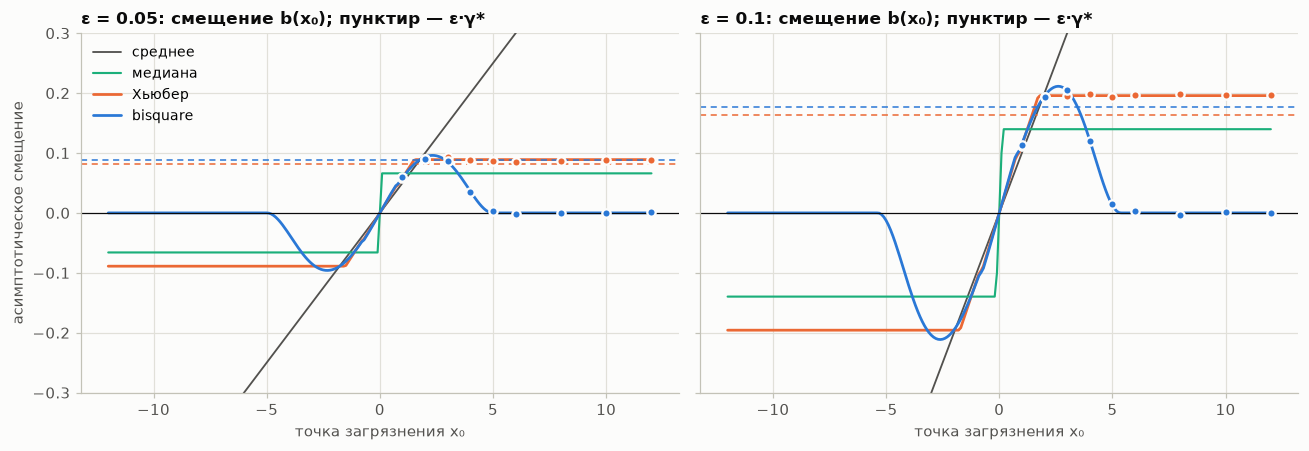

In [7]:
ZG = np.linspace(-9, 9, 6001)
WG = np.full(ZG.size, ZG[1] - ZG[0])
WG[[0, -1]] /= 2
WG *= stats.norm.pdf(ZG)


def mass_inside(d, m, eps):
    return (1 - eps) * (stats.norm.cdf(m + d) - stats.norm.cdf(m - d))


def median_mix(eps, x0):
    t1 = stats.norm.ppf(0.5 / (1 - eps))
    t2 = stats.norm.ppf((0.5 - eps) / (1 - eps))
    at_x0 = (1 - eps) * stats.norm.cdf(x0) + eps >= 0.5
    return np.where(t1 < x0, t1, np.where(at_x0, x0, t2))


def mad_mix(eps, x0, m):
    out = np.empty(len(x0))
    for i, (xi, mi) in enumerate(zip(x0, m)):
        d0 = abs(xi - mi)
        if mass_inside(d0, mi, eps) >= 0.5:
            out[i] = optimize.brentq(lambda d, mi=mi: mass_inside(d, mi, eps) - 0.5, 0, d0)
        elif mass_inside(d0, mi, eps) + eps >= 0.5:
            out[i] = d0
        else:
            out[i] = optimize.brentq(lambda d, mi=mi: mass_inside(d, mi, eps) + eps - 0.5, d0, 50)
    return out


def asym_bias(P, c, eps, x0, tol=1e-10, maxit=5000):
    x0 = np.asarray(x0, dtype=float)
    m = median_mix(eps, x0)
    s = mad_mix(eps, x0, m) / Q_PHI
    t = m.copy()
    for _ in range(maxit):
        wz = P.w((ZG[None, :] - t[:, None]) / s[:, None], c) * WG
        wo = P.w((x0 - t) / s, c)
        t_new = ((1 - eps) * (wz @ ZG) + eps * wo * x0) / ((1 - eps) * wz.sum(axis=1) + eps * wo)
        if np.max(np.abs(t_new - t)) < tol:
            return t_new
        t = t_new
    warnings.warn('asym_bias: итерации не сошлись')
    return t


x0_grid = np.linspace(-12, 12, 241)
x0_pts = np.array([1, 2, 3, 4, 5, 6, 8, 10, 12])
rng = np.random.default_rng(SEED + 4)
n_big, reps = 20_000, 10
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, eps in zip(axes, [0.05, 0.10]):
    ax.plot(x0_grid, eps * x0_grid, color=COLORS['среднее'], lw=1.2, label='среднее')
    ax.plot(x0_grid, median_mix(eps, x0_grid), color=COLORS['медиана'], lw=1.4, label='медиана')
    for P, c, ges in [(HUBER, K95, GES_H), (BISQ, C95, GES_B)]:
        ax.plot(x0_grid, asym_bias(P, c, eps, x0_grid), color=COLORS[P.name], label=f'{P.name}')
        ax.axhline(eps * ges, color=COLORS[P.name], **BOUND)
        emp = []
        for x in x0_pts:
            X = rng.standard_normal((reps, n_big))
            X[:, :int(eps * n_big)] = x
            emp.append(m_location(X, P, c, mad(X) / Q_PHI).mean())
        ax.scatter(x0_pts, emp, s=30, color=COLORS[P.name], edgecolor=SURFACE, linewidth=1.5, zorder=4)
    ax.axhline(0, **REF)
    ax.set(title=f'ε = {eps:g}: смещение b(x₀); пунктир — ε·γ*', xlabel='точка загрязнения x₀', ylim=(-0.3, 0.3))
axes[0].set_ylabel('асимптотическое смещение')
axes[0].legend(loc='upper left')
fig.tight_layout()
plt.show()

In [8]:
x0_fine = np.linspace(0, 15, 301)
rows = []
for eps in EPS_LIST:
    b_bisq = asym_bias(BISQ, C95, eps, x0_fine)
    rows.append({'ε': eps,
                 'Хьюбер: ε·γ*': eps * GES_H, 'Хьюбер: MB (x₀ → ∞)': asym_bias(HUBER, K95, eps, [1e4])[0],
                 'bisquare: ε·γ*': eps * GES_B, 'bisquare: max b(x₀)': b_bisq.max(),
                 'bisquare: argmax x₀': x0_fine[b_bisq.argmax()]})
show(pd.DataFrame(rows).set_index('ε'), formats={'bisquare: argmax x₀': '{:.2f}'})

,Хьюбер: ε·γ*,Хьюбер: MB (x₀ → ∞),bisquare: ε·γ*,bisquare: max b(x₀),bisquare: argmax x₀
ε,,,,,
0.010000,0.016375,0.016634,0.017696,0.017969,2.15
0.050000,0.081875,0.088946,0.088478,0.096011,2.35
0.100000,0.163750,0.195757,0.176956,0.211365,2.60
0.200000,0.327499,0.502136,0.353913,0.543306,3.45


Точки моделирования ложатся на теоретические кривые. У Хьюбера $b(x_0)$ монотонно растёт и выходит на предел при $x_0\to\infty$, это и есть MB. У bisquare максимум достигается при конечном $x_0$, а далёкие выбросы ($x_0\gtrsim c\,\sigma_\infty$) вообще не влияют. У медианы смещение ограничено, у среднего растёт линейно. Оценка $\varepsilon\gamma^*$ хорошо работает при малых $\varepsilon$ (при $\varepsilon=0.01$: 0.0164 против точного 0.0166), а при больших занижает MB (при $\varepsilon=0.1$: 0.164 против 0.196 у Хьюбера). Причина в том, что выбросы раздувают ещё и MAD, и зависимость от $\varepsilon$ перестаёт быть линейной. У bisquare максимум смещения чуть больше, чем у Хьюбера, и достигается при $x_0\approx2$–$3.5\sigma$.

### 3.5. Распределение Коши

$X\sim\mathrm{Cauchy}(\mu,\gamma)$. MAD состоятелен для $\gamma$ ($F^{-1}(3/4)=\gamma$), а $\mathrm{MADN}\to\sigma_\infty=\gamma/0.6745$. Тогда $V=X/\sigma_\infty\sim\mathrm{Cauchy}(0,g)$, $g=0.6745$, и
$$
\mathrm{AV}(\hat\mu)=\sigma_\infty^2\,\frac{\mathrm E\psi^2(V)}{(\mathrm E\psi'(V))^2},\qquad
\text{Хьюбер: }\ \mathrm E\psi'=\tfrac2\pi\operatorname{arctg}\tfrac kg,\quad
\mathrm E\psi^2=\tfrac{2g}{\pi}\Big(k-g\operatorname{arctg}\tfrac kg\Big)+k^2\Big(1-\tfrac2\pi\operatorname{arctg}\tfrac kg\Big),
$$
для bisquare — через $C_m=\tfrac g\pi J_m$, $J_0=\tfrac2g\operatorname{arctg}\tfrac cg$, $J_m=\tfrac{2c^{2m-1}}{2m-1}-g^2J_{m-1}$. Константы те же: $k=1.345$, $c=4.685$. Ориентиры: медиана $\pi^2\gamma^2/4$, граница Рао–Крамера $2\gamma^2$ ($I=1/(2\gamma^2)$), у среднего AV бесконечна. Для $\gamma$: $\mathrm{AV}(\mathrm{MAD})=\dfrac{1}{16f(q)^2}\Big|_{q=\gamma}=\dfrac{\pi^2}{4}\gamma^2$, граница тоже $2\gamma^2$.

In [9]:
def av_cauchy(P, c):
    e_dpsi, e_psi2 = moments(P, c, trunc_cauchy(c, Q_PHI))
    return e_psi2 / e_dpsi ** 2 / Q_PHI ** 2


cauchy_v = stats.cauchy(scale=Q_PHI).pdf
for P, c in [(HUBER, K95), (BISQ, C95)]:
    num = (expect(lambda u, P=P, c=c: P.psi(u, c) ** 2, cauchy_v, (c,))
           / expect(lambda u, P=P, c=c: P.dpsi(u, c), cauchy_v, (c,)) ** 2 / Q_PHI ** 2)
    print(f'{P.name}: точно {av_cauchy(P, c):.10f}, квадратура {num:.10f}')

rng = np.random.default_rng(SEED + 5)
n, M = 400, 4000
X = rng.standard_cauchy((M, n))
D = mad(X)
S = D / Q_PHI
loc = {'Хьюбер 1.345': (m_location(X, HUBER, K95, S), av_cauchy(HUBER, K95)),
       'bisquare 4.685': (m_location(X, BISQ, C95, S), av_cauchy(BISQ, C95)),
       'медиана': (np.median(X, axis=1), np.pi ** 2 / 4),
       'среднее': (X.mean(axis=1), np.inf)}
rows = [{'параметр': 'μ', 'оценка': name, 'AV/γ² (теория)': av, 'n·Var/γ² (МК)': n * t.var(),
         'эффективность': 2 / av} for name, (t, av) in loc.items()]
rows.append({'параметр': 'γ', 'оценка': 'MAD', 'AV/γ² (теория)': np.pi ** 2 / 4, 'n·Var/γ² (МК)': n * D.var(),
             'эффективность': 2 / (np.pi ** 2 / 4)})
cauchy_tab = pd.DataFrame(rows).set_index(['параметр', 'оценка'])
cauchy_tab['отклонение МК, %'] = 100 * (cauchy_tab['n·Var/γ² (МК)'] / cauchy_tab['AV/γ² (теория)'] - 1)
cauchy_tab.loc[('μ', 'среднее'), 'отклонение МК, %'] = np.nan
print(f'E MAD = {D.mean():.4f} (γ = 1)')
show(cauchy_tab, formats={'n·Var/γ² (МК)': '{:.4g}', 'эффективность': '{:.1%}', 'отклонение МК, %': '{:.1f}'})

Хьюбер: точно 3.5142416652, квадратура 3.5142416652
bisquare: точно 2.7897649460, квадратура 2.7897649460
E MAD = 1.0023 (γ = 1)


In [10]:
c_opt_b = optimize.minimize_scalar(lambda c: av_cauchy(BISQ, c), bounds=(0.5, 10), method='bounded').x
k_opt_h = optimize.minimize_scalar(lambda k: av_cauchy(HUBER, k), bounds=(0.01, 5), method='bounded').x
print(f'если подбирать под Коши: bisquare c = {c_opt_b:.3f} -> эффективность {2 / av_cauchy(BISQ, c_opt_b):.1%}, '
      f'Хьюбер k = {k_opt_h:.3f} -> {2 / av_cauchy(HUBER, k_opt_h):.1%}')

если подбирать под Коши: bisquare c = 2.210 -> эффективность 90.2%, Хьюбер k = 0.266 -> 87.8%


Теория и моделирование совпадают. С константами, подобранными под нормальный закон, на Коши обе M-оценки проигрывают медиане: Хьюбер даёт 57 %, bisquare 72 %, медиана 81 %. Порог $c\sigma_\infty\approx6.9\gamma$ слишком большой, и тяжёлые хвосты Коши попадают в оценку. Если подобрать константы под Коши, обе оценки обгоняют медиану: bisquare ($c\approx2.2$) даёт 90 %, Хьюбер ($k\approx0.27$) — 88 %.

## Выводы

1. IF и GES посчитаны для среднего ($\gamma^*=\infty$), медианы (1.25), $\bar x_{0.1}$ (1.60), Хьюбера (1.64) и bisquare (1.77); sensitivity curves с ними совпадают, а $v^2=\mathrm E\,\mathrm{IF}^2$ подтверждено моделированием.
2. Информативность оценки ($R^2$) держится около 1 до точки срыва и сразу после неё падает почти до нуля; для $\bar x_{0.25}$ это происходит ровно при 26 выбросах из 100.
3. Для эффективности $\Delta=0.95$ при MAD-масштабе нужны $k=1.345$ и $c=4.685$; $\mathrm{MB}(\varepsilon)\approx\varepsilon\gamma^*$ годится при малых $\varepsilon$. По графикам $b(x_0)$: у Хьюбера смещение растёт до предела, у bisquare далёкие выбросы не влияют.
4. На Коши с теми же константами Хьюбер (57 %) и bisquare (72 %) хуже медианы (81 %). Если подобрать константы под Коши, получается 88 % и 90 %, так что константы нужно подбирать под модель.